# 🧠 Neural Network — Regression (7 Features → 1 Output)

Architecture: **Linear(7→50) → ReLU → Linear(50→40) → ReLU → Linear(40→1)**

We generate synthetic data, train the model, and visualize the results.

## 1. Imports

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# ── reproducibility ──────────────────────────────────────────
torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## 2. Synthetic Dataset

We create 1 000 samples with **7 features**. The target is a noisy linear combination:

$$y = 3x_1 - 2x_2 + x_3 + 0.5x_4 - x_5 + 2x_6 - 1.5x_7 + \epsilon$$

In [2]:
N        = 1_000          # number of samples
nfeature = 7              # must match model input size

# Raw numpy data
X_np = np.random.randn(N, nfeature).astype(np.float32)
weights = np.array([3.0, -2.0, 1.0, 0.5, -1.0, 2.0, -1.5], dtype=np.float32)
noise   = 0.5 * np.random.randn(N).astype(np.float32)
y_np    = X_np @ weights + noise          # shape (N,)

# ── train / val split (80 / 20) ──────────────────────────────
split    = int(0.8 * N)
X_train  = torch.from_numpy(X_np[:split]).to(device)
y_train  = torch.from_numpy(y_np[:split]).unsqueeze(1).to(device)  # (800,1)
X_val    = torch.from_numpy(X_np[split:]).to(device)
y_val    = torch.from_numpy(y_np[split:]).unsqueeze(1).to(device)  # (200,1)

print(f'Train: X={X_train.shape}  y={y_train.shape}')
print(f'Val  : X={X_val.shape}    y={y_val.shape}')

Train: X=torch.Size([800, 7])  y=torch.Size([800, 1])
Val  : X=torch.Size([200, 7])    y=torch.Size([200, 1])


## 3. Model Definition

> **Bug fixed**: the original notebook had `nn.RelU()` (capital U, wrong case). Corrected to `nn.ReLU()`.

In [3]:
model = nn.Sequential(
    nn.Linear(nfeature, 50),
    nn.ReLU(),              # ← was nn.RelU()  (typo fixed)
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1)
).to(device)

print(model)
total_params = sum(p.numel() for p in model.parameters())
print(f'\nTotal trainable parameters: {total_params:,}')

Sequential(
  (0): Linear(in_features=7, out_features=50, bias=True)
  (1): ReLU()
  (2): Linear(in_features=50, out_features=40, bias=True)
  (3): ReLU()
  (4): Linear(in_features=40, out_features=1, bias=True)
)

Total trainable parameters: 2,481


## 4. Loss, Optimizer & Training Loop

In [4]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)


def train(model, optimizer, criterion, Xtrain, Ytrain, epochs=200):
    """Train loop — returns (train_losses, val_losses)."""
    train_losses = []
    val_losses   = []

    for epoch in range(1, epochs + 1):
        # ── forward + backward ───────────────────────────────
        model.train()
        Y_pred = model(Xtrain)
        loss   = criterion(Y_pred, Ytrain)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        train_losses.append(loss.item())

        # ── validation (no gradient needed) ──────────────────
        model.eval()
        with torch.no_grad():
            val_pred = model(X_val)
            val_loss = criterion(val_pred, y_val)
        val_losses.append(val_loss.item())

        if epoch % 20 == 0 or epoch == 1:
            print(f'Epoch {epoch:>3d}/{epochs}  '
                  f'Train Loss: {loss.item():.4f}  '
                  f'Val Loss: {val_loss.item():.4f}')

    return train_losses, val_losses


train_losses, val_losses = train(
    model, optimizer, criterion,
    X_train, y_train,
    epochs=200
)

Epoch   1/200  Train Loss: 21.6362  Val Loss: 23.0625
Epoch  20/200  Train Loss: 19.6279  Val Loss: 21.0065
Epoch  40/200  Train Loss: 15.4877  Val Loss: 16.7135
Epoch  60/200  Train Loss: 8.7087  Val Loss: 9.6661
Epoch  80/200  Train Loss: 2.7687  Val Loss: 3.2343
Epoch 100/200  Train Loss: 0.9916  Val Loss: 1.0858
Epoch 120/200  Train Loss: 0.7042  Val Loss: 0.7174
Epoch 140/200  Train Loss: 0.5559  Val Loss: 0.6084
Epoch 160/200  Train Loss: 0.4710  Val Loss: 0.5296
Epoch 180/200  Train Loss: 0.4142  Val Loss: 0.4650
Epoch 200/200  Train Loss: 0.3770  Val Loss: 0.4245


## 5. Learning Curve

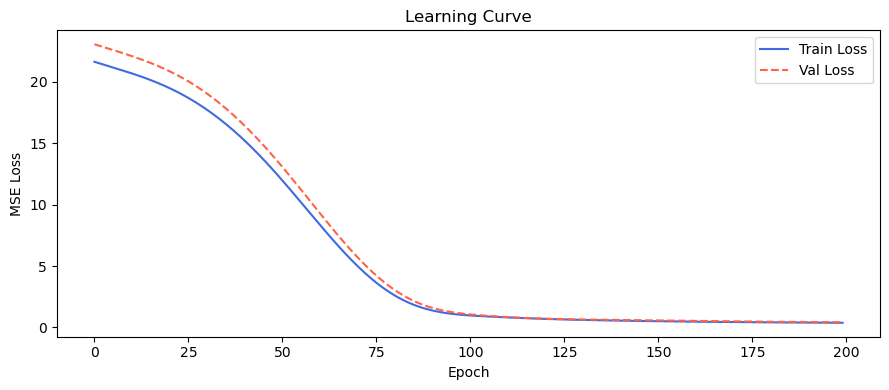

Saved → learning_curve.png


In [5]:
plt.figure(figsize=(9, 4))
plt.plot(train_losses, label='Train Loss', color='royalblue')
plt.plot(val_losses,   label='Val Loss',   color='tomato', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Learning Curve')
plt.legend()
plt.tight_layout()
plt.savefig('learning_curve.png', dpi=150)
plt.show()
print('Saved → learning_curve.png')

## 6. Evaluation — Predicted vs. Actual

Validation R²   : 0.9816
Validation RMSE : 0.6516


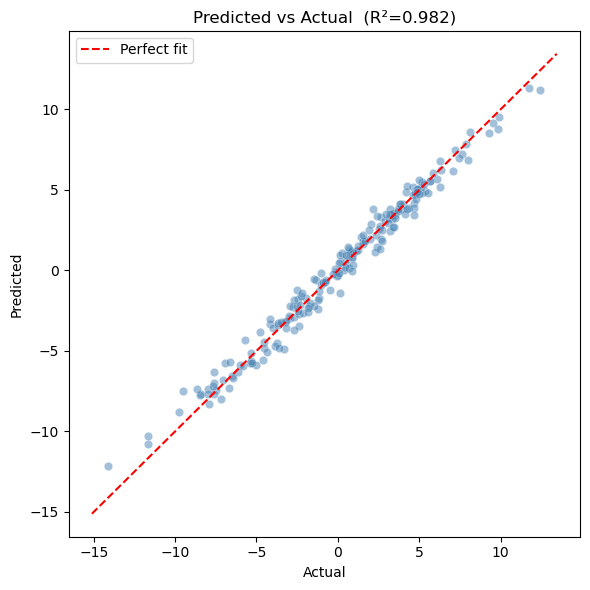

Saved → pred_vs_actual.png


In [6]:
model.eval()
with torch.no_grad():
    preds = model(X_val).cpu().numpy().flatten()
actuals = y_val.cpu().numpy().flatten()

# ── R² score (manual, no sklearn needed) ─────────────────────
ss_res = np.sum((actuals - preds) ** 2)
ss_tot = np.sum((actuals - actuals.mean()) ** 2)
r2     = 1 - ss_res / ss_tot
rmse   = np.sqrt(np.mean((actuals - preds) ** 2))

print(f'Validation R²   : {r2:.4f}')
print(f'Validation RMSE : {rmse:.4f}')

# ── scatter plot ─────────────────────────────────────────────
plt.figure(figsize=(6, 6))
plt.scatter(actuals, preds, alpha=0.5, color='steelblue', edgecolors='white', linewidths=0.3)
lim = (min(actuals.min(), preds.min()) - 1,
       max(actuals.max(), preds.max()) + 1)
plt.plot(lim, lim, 'r--', linewidth=1.5, label='Perfect fit')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title(f'Predicted vs Actual  (R²={r2:.3f})')
plt.legend()
plt.tight_layout()
plt.savefig('pred_vs_actual.png', dpi=150)
plt.show()
print('Saved → pred_vs_actual.png')

## 7. Save & Load the Model

In [7]:
# ── save ─────────────────────────────────────────────────────
torch.save(model.state_dict(), 'model_weights.pth')
print('Model weights saved → model_weights.pth')

# ── reload and verify ────────────────────────────────────────
loaded_model = nn.Sequential(
    nn.Linear(nfeature, 50),
    nn.ReLU(),
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1)
).to(device)
loaded_model.load_state_dict(torch.load('model_weights.pth', weights_only=True))
loaded_model.eval()

with torch.no_grad():
    sample_input  = torch.randn(1, nfeature, device=device)
    sample_output = loaded_model(sample_input)
print(f'Inference on a random sample → {sample_output.item():.4f}')
print('✅ Model loaded and inference successful!')

Model weights saved → model_weights.pth
Inference on a random sample → 0.8544
✅ Model loaded and inference successful!
